In [2]:
import pandas as pd

stocks = pd.read_csv("tickers.csv")

companies = stocks[stocks["primary_line"]]

companies.to_csv("deduplicated_tickers.csv", index=False)

In [ ]:
import yfinance as yf
import pandas as pd

ticker = "ARP.ST"

data = yf.Ticker(ticker)
balance_sheet = data.quarterly_income_stmt

with pd.option_context("display.max_rows", None):
    display(balance_sheet)

,2026-06-30,2026-03-31,2025-12-31,2025-09-30,2025-06-30,2025-03-31
Tax Effect Of Unusual Items,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
Tax Rate For Calcs,1.900000e-01,1.211290e-01,1.375020e-01,1.900000e-01,1.578930e-01,NaN
Normalized EBITDA,9.833000e+06,5.318000e+06,-1.300200e+07,3.907300e+07,-5.239500e+07,NaN
Net Income From Continuing Operation Net Minority Interest,-3.441500e+07,-2.138400e+07,-4.292000e+07,2.084000e+06,-4.542300e+07,NaN
Reconciled Depreciation,3.827000e+07,3.872800e+07,9.218200e+07,3.435700e+07,3.464600e+07,NaN
Reconciled Cost Of Revenue,6.769640e+08,7.458450e+08,8.198240e+08,6.874430e+08,7.506810e+08,NaN
EBITDA,9.833000e+06,5.318000e+06,-1.300200e+07,3.907300e+07,-5.239500e+07,NaN
EBIT,-2.843700e+07,-3.341000e+07,-1.051840e+08,4.716000e+06,-8.704100e+07,NaN
Net Interest Income,-3.438000e+06,-1.968000e+06,8.248000e+06,-1.158300e+07,-5.960000e+05,NaN
Interest Expense,4.695000e+06,4.723000e+06,-1.781800e+07,1.180900e+07,2.051000e+06,NaN


In [15]:
import yfinance as yf
import numpy as np
import pandas as pd

ticker = "ARP.ST"

data = yf.Ticker(ticker)
incm_stmt = data.income_stmt

def get_nth(income_statement: pd.DataFrame, index: str, n: int):
    if index not in income_statement.index:
        return None
    item = income_statement.loc[index].dropna().sort_index()
    if item.empty:
        return None
    return item.iloc[-n]

def get_latest(income_statement: pd.DataFrame, index: str):
    return get_nth(income_statement, index, 1)

def get_second(income_statement: pd.DataFrame, index: str):
    return get_nth(income_statement, index, 2)

def get_growth(income_statement: pd.DataFrame, index: str):
    r = get_latest(income_statement, index)
    latest = None
    if isinstance(r, float):
        latest = r
    else: 
        return None

    r = get_nth(income_statement, index, 5)
    year_ago = None
    if isinstance(r, float):
        if(r != 0.0):
            year_ago = r
        else:
            year_ago = 1
    else:
        return None

    return ((latest - year_ago) / year_ago)

df = pd.DataFrame([{
        "ticker": ticker,
        "industry": data.info.get("industry", ""),
        "sector": data.info.get("sector", ""),
        "enterpriseValue": data.info.get("enterpriseValue", np.nan),
        "debt": get_latest(data.quarterly_balance_sheet, "Total Debt"),
        "assets": get_latest(data.quarterly_balance_sheet, "Total Assets"),
        "revenue": get_latest(data.quarterly_income_stmt, "Total Revenue"),
        "EBIT": get_latest(data.quarterly_income_stmt, "EBIT"),
        "profit": get_latest(data.quarterly_income_stmt, "Net Income"),
        "revenue_growth": get_growth(data.quarterly_income_stmt, "Total Revenue"),
        #"earnings_growth": data.info.get("earningsGrowth", np.nan)
    }])

display(df)

,ticker,industry,sector,enterpriseValue,debt,assets,revenue,EBIT,profit,revenue_growth
0,ARP.ST,Paper & Paper Products,Basic Materials,NaN,333603000.0,2.652381e+09,750827000.0,-28437000.0,-34415000.0,-0.099139


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

def get_nth(income_statement: pd.DataFrame, index: str, n: int):
    if index not in income_statement.index:
        return None
    item = income_statement.loc[index].dropna().sort_index()
    if item.empty:
        return None
    try:
        return item.iloc[-n]
    except IndexError:
        return None

def get_latest(income_statement: pd.DataFrame, index: str):
    return get_nth(income_statement, index, 1)

def get_second(income_statement: pd.DataFrame, index: str):
    return get_nth(income_statement, index, 2)

def get_growth_features(stmt: pd.DataFrame, index: str):
    latest = get_latest(stmt, index)
    prior = get_nth(stmt, index, 5)

    if latest is None or prior is None:
        return {"prior": np.nan, "growth": np.nan, "state": "unknown"}
    if prior > 0:
        growth, state = (latest - prior) / prior, "normal"
    elif prior < 0:
        growth, state = np.nan, "negative_base"
    elif latest > 0:
        growth, state = np.nan, "initial"
    else:
        growth, state = np.nan, "none"

    return {"prior": prior, "growth": growth, "state": state}

yf_data = []
for ticker in companies["yf_ticker"]:
    data = yf.Ticker(ticker)

    revenue_growth_feature = get_growth_features(data.quarterly_income_stmt, "Total Revenue")
    earnings_growth_feature = get_growth_features(data.quarterly_income_stmt, "EBIT")
    
    yf_data.append({
        "ticker": ticker,
        "industry": data.info.get("industry", ""),
        "sector": data.info.get("sector", ""),
        "enterpriseValue": data.info.get("enterpriseValue", np.nan),
        "debt": get_latest(data.quarterly_balance_sheet, "Total Debt"),
        "assets": get_latest(data.quarterly_balance_sheet, "Total Assets"),
        "revenue": get_latest(data.quarterly_income_stmt, "Total Revenue"),
        "EBIT": get_latest(data.quarterly_income_stmt, "EBIT"),
        "profit": get_latest(data.quarterly_income_stmt, "Net Income"),
        "revenue_state": revenue_growth_feature["state"],
        "revenue_growth": revenue_growth_feature["growth"],
        "revenue_prior": revenue_growth_feature["prior"],
        "earnings_state": earnings_growth_feature["state"],
        "earnings_growth": earnings_growth_feature["growth"],
        "earnings_prior": earnings_growth_feature["prior"]
    })

company_data = pd.DataFrame(yf_data)
company_data.to_csv("company_data.csv")
company_data.head()


KeyError: 'revenue_state'

In [14]:
with pd.option_context("display.max_rows", None):
    print(company_data.isna().any(axis='columns').value_counts())
    print(company_data[company_data.isna().any(axis='columns')])

False    320
True      46
Name: count, dtype: int64
           ticker                                  industry  \
22         ARP.ST                    Paper & Paper Products   
23   ARION-SDB.ST                          Banks - Regional   
35         AZA.ST                          Banks - Regional   
36      AVARDA.ST                       Banks - Diversified   
54      BIOG-B.ST  Drug Manufacturers - Specialty & Generic   
88      CRED-A.ST                          Asset Management   
99        EAST.ST                      Real Estate Services   
105      ELLOS.ST                           Internet Retail   
113      ENITY.ST                          Mortgage Finance   
119        EQT.ST                          Asset Management   
137       G5EN.ST            Electronic Gaming & Multimedia   
146     HAKI-B.ST                         Metal Fabrication   
149      HAV-B.ST                           Capital Markets   
157       HOFI.ST                           Credit Services   
159

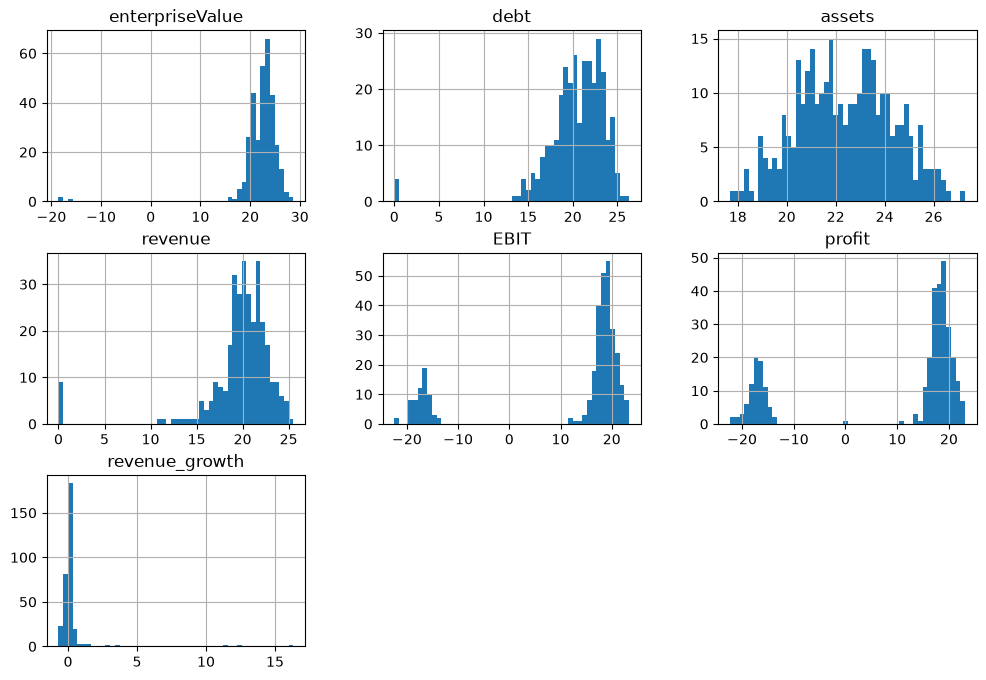

In [31]:
import matplotlib.pyplot as plt
import numpy as np
trimmed_company_data = company_data[~company_data.isna().any(axis="columns")]
trimmed_company_data = trimmed_company_data[~((trimmed_company_data == np.nan)).any(axis="columns")]
company_data_log = np.sign(trimmed_company_data.select_dtypes("number")) * np.log1p(trimmed_company_data.select_dtypes("number").abs())
#with pd.option_context("display.max_rows", None):
    #display(trimmed_company_data)
    #display(company_data_log)
#display(company_data_log)

pd.DataFrame(company_data_log).hist(bins=50, figsize=(12, 8))
plt.show()